# Health, regression and correlations: the earlier evidence
**Companion to [SSL and filtering](01_ssl_filtering_summary.ipynb) · saved studies from 6–8 October 2026 · seven figures**

**Health showed conditional predictive signal; reliable action selection remained unproven.** This notebook separates ranking images, forecasting action benefits, transferring a target across labeled panels, and obtaining a controller gain. They are different tests.

The earlier **alpha** actuator ranked images for admission; replay actions **8 / 16 / 24** changed replay allocation within a fixed 32-image update. These are distinct from today's full/half frame-processing rate. Historical readers were fixed-head CE, kNN or linear probe—not the current primary fine-tuning reader. CE is classification cross-entropy, not SSL reconstruction loss; **pp** means percentage points of accuracy, not detection mAP.

All graphs read archived results; no training or predictor fitting occurs here. Reused panels, tiny stream/pool samples and correlated repeats limit generalization. Displayed correlations and means are descriptive, without invented independent-sample confidence intervals.


In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'cafl4ds').is_dir() and (p / 'pyproject.toml').exists())
OUT = ROOT / 'outputs/research-summary/20261012-health-regression-history'
D = json.loads((OUT / 'metrics.json').read_text())
for relative, digest in D['sources'].items():
    assert hashlib.sha256((ROOT / relative).read_bytes()).hexdigest() == digest, relative
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 11, 'axes.titlesize': 13,
    'axes.spines.top': False, 'axes.spines.right': False, 'figure.facecolor': 'white'})
BLUE, ORANGE, TEAL, GREY = '#2877b5', '#cd7540', '#168577', '#677585'

def finish(fig, name):
    fig.savefig(OUT / (name + '.png'), dpi=180, bbox_inches='tight')
    fig.savefig(OUT / (name + '.svg'), bbox_inches='tight')
    plt.show()

def bars(ax, labels, series, xlabel):
    y = np.arange(len(labels))
    width = .7 / len(series)
    for index, (name, values, color) in enumerate(series):
        ax.barh(y + (index - (len(series)-1)/2) * width, values, height=width*.9, label=name, color=color)
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.axvline(0, color=GREY, linewidth=.8)
    ax.set_xlabel(xlabel)
    ax.legend(frameon=False, fontsize=9, loc='upper left', bbox_to_anchor=(0,-.2), ncol=2, borderaxespad=0)
    ax.xaxis.set_major_locator(MaxNLocator(5))


## 1. Image ranking: health interactions helped, but time transfer failed
Ridge predictors ranked 16 candidate images by their four-update **fixed-head CE benefit**. Hyperparameters used validation; the tests held out a seed or the final visit's candidate images. Adding image–health interactions improved held-out-seed rank correlation from **0.075 to 0.363**, but it remained **−0.071** on the time holdout. Every displayed selector lost to random on that time holdout.

Health alone is constant within a saved state, so it cannot rank that state's candidates. Interactions let the same image feature matter differently under different model health. These results concern image ranking, not replay or frame-rate control.


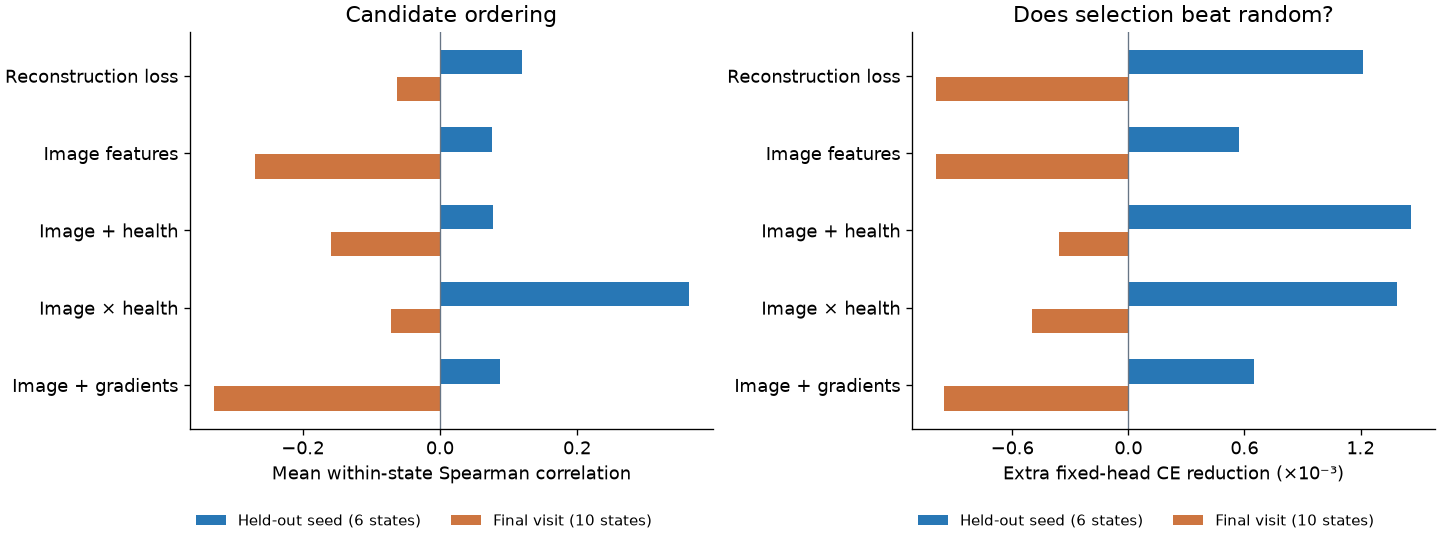

In [2]:
p = pd.DataFrame(D['ranking']); labels = p.model.drop_duplicates().tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
for ax, metric, scale, title, xlabel in [
    (axes[0], 'rank', 1, 'Candidate ordering', 'Mean within-state Spearman correlation'),
    (axes[1], 'extra_ce_reduction', 1000, 'Does selection beat random?', 'Extra fixed-head CE reduction (×10⁻³)')]:
    series = [(name, p[p.split == key].set_index('model').loc[labels, metric].to_numpy()*scale, color)
              for key, name, color in [('test_seed', 'Held-out seed (6 states)', BLUE), ('test_time', 'Final visit (10 states)', ORANGE)]]
    bars(ax, labels, series, xlabel); ax.set_title(title)
finish(fig, '01_image_health_transfer')


## 2. Action regression: a better training fit was not a better forecast
The next ridge model predicted changes from alternative alpha schedules. The fit set had **12 states**; validation had **four**. Action/history information helped validation, while adding health made validation error worse than predicting no benefit. The health model's mean state-wise rank correlation moved from **0.83 in fitting to −0.35 in validation**.

The dashed reference below is the zero-benefit predictor. Ratios are normalized separately within each split, so they compare models with that split's baseline—not the absolute difficulty of fitting versus validation. The underlying target was refitted classification CE.


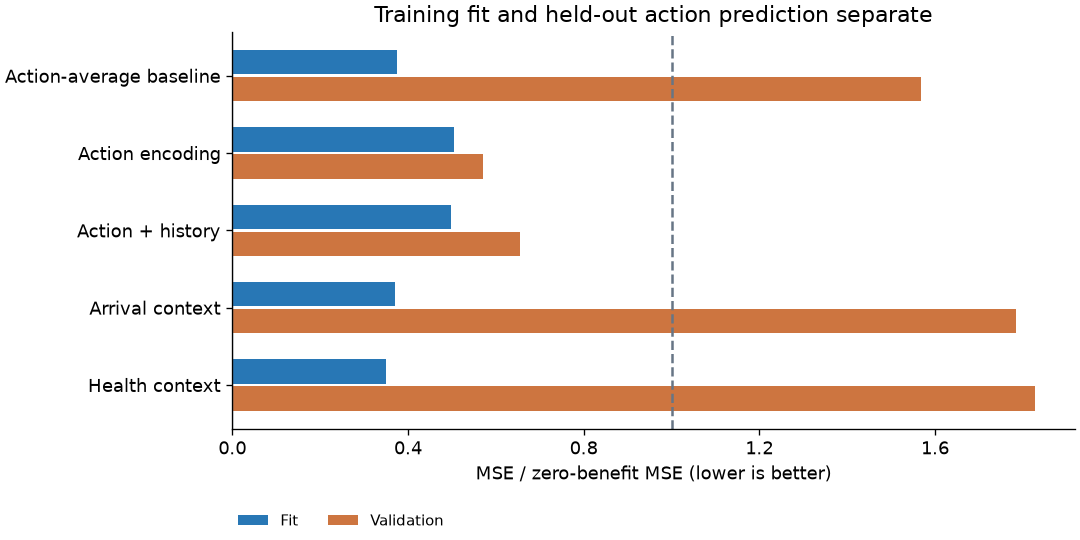

In [3]:
p = pd.DataFrame(D['action_models']); names = ['action_mean','action','history','arrival','health']
labels = ['Action-average baseline','Action encoding','Action + history','Arrival context','Health context']
fig, ax = plt.subplots(figsize=(9, 4.5), layout='constrained')
bars(ax, labels, [(split.title(), p[p.split == split].set_index('model').loc[names, 'relative_mse'].to_numpy(), color)
                 for split, color in [('fit', BLUE), ('validation', ORANGE)]], 'MSE / zero-benefit MSE (lower is better)')
ax.axvline(1, color=GREY, linestyle='--'); ax.set_title('Training fit and held-out action prediction separate')
finish(fig, '02_action_regression')


## 3. A task-representative teacher still did not rescue health regression
Later models fitted ridge regression to development-query action benefits, with whole original image pools held out and train-only normalization. The primary four-update set had **24 states**, with 16 used in each outer fit. Runtime features included composition, reconstruction, gradient statistics and health levels; fitting targets required labels.

Every displayed model had negative replication-panel forecast skill. **Skill = 100 × (1 − model MSE / zero-benefit MSE)**: 0% ties the baseline, negative values are worse. Health's CE correlation was **−0.363**, with **−7.65% skill**. The lower panels show its actual forecasts; positive accuracy correlation still did not produce positive MSE skill. The targets use different units.


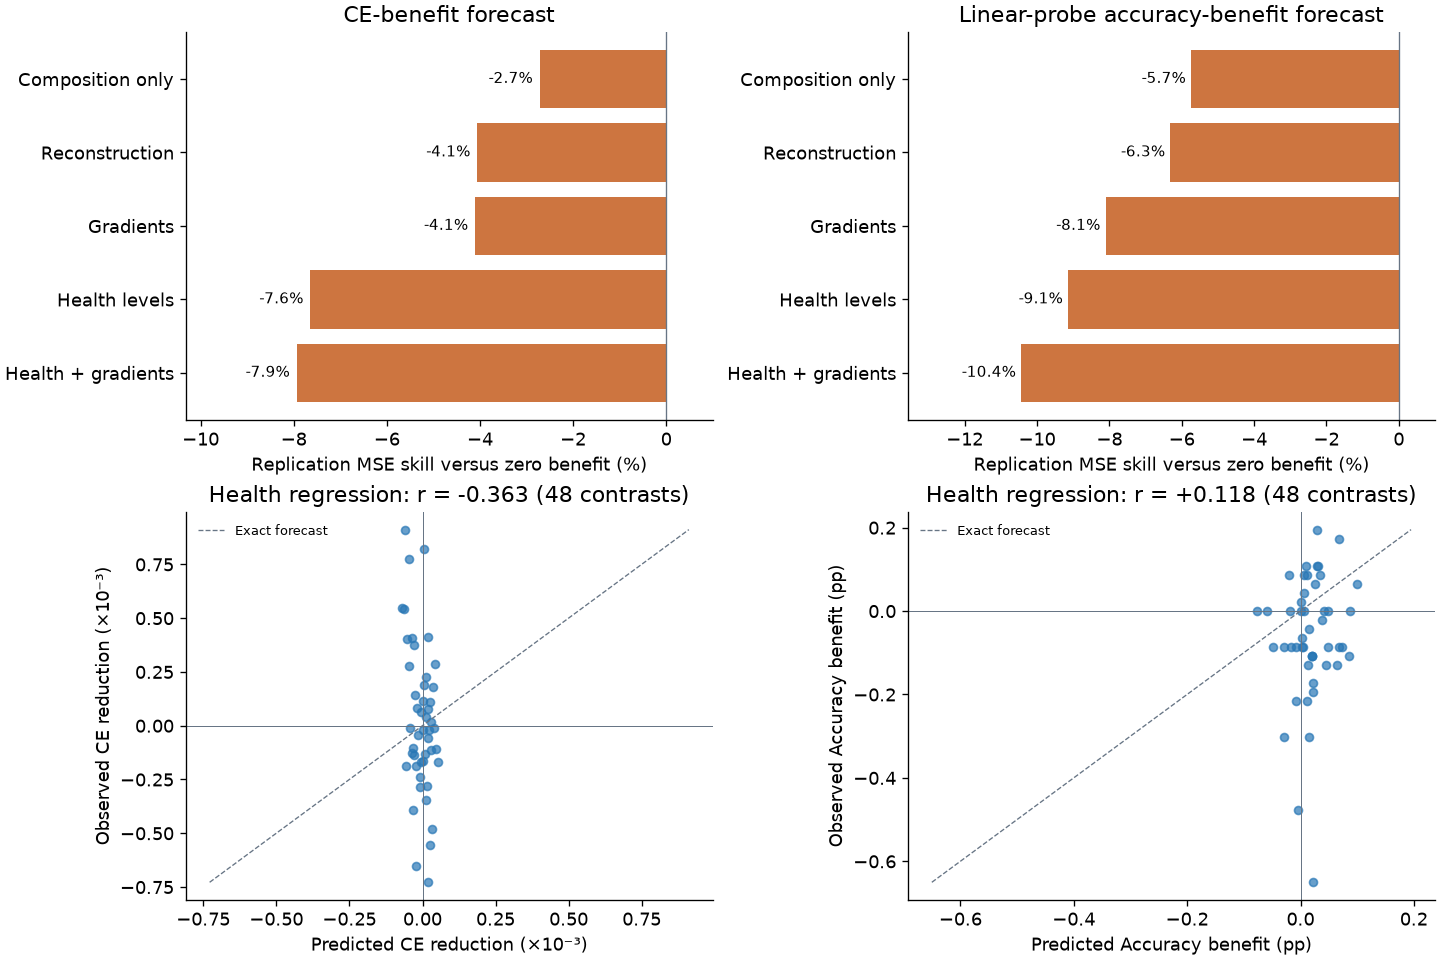

In [4]:
p = pd.DataFrame(D['forecast_skill']); labels = p.model.drop_duplicates().tolist()
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout='constrained')
for ax, target, title in zip(axes[0], ['ce','accuracy'], ['CE-benefit forecast','Linear-probe accuracy-benefit forecast']):
    values = p[p.target == target].set_index('model').loc[labels, 'mse_skill_vs_zero'].to_numpy()*100
    ax.barh(labels, values, color=[TEAL if v > 0 else ORANGE for v in values]); ax.invert_yaxis()
    ax.axvline(0, color=GREY, linewidth=.8); ax.set_xlabel('Replication MSE skill versus zero benefit (%)'); ax.set_title(title)
    for i, value in enumerate(values): ax.text(value-.15, i, f'{value:+.1f}%', ha='right', va='center', fontsize=9)
    ax.set_xlim(min(values)*1.3, 1)
points = pd.DataFrame(D['health_scatter'])
for ax, target, scale, unit in zip(axes[1], ['ce','accuracy'], [1000,100], ['CE reduction (×10⁻³)','Accuracy benefit (pp)']):
    part = points[points.target == target]; x, y = part.prediction.to_numpy()*scale, part.observation.to_numpy()*scale
    ax.scatter(x,y, s=23, color=BLUE, alpha=.7)
    lo, hi = min(x.min(),y.min()), max(x.max(),y.max())
    ax.plot([lo,hi],[lo,hi], '--', color=GREY, linewidth=.8, label='Exact forecast')
    ax.axhline(0,color=GREY,linewidth=.6); ax.axvline(0,color=GREY,linewidth=.6)
    ax.set_xlabel('Predicted '+unit); ax.set_ylabel('Observed '+unit)
    ax.set_title(f'Health regression: r = {np.corrcoef(x,y)[0,1]:+.3f} (48 contrasts)')
    ax.legend(frameon=False, fontsize=8, loc='upper left')
finish(fig, '03_health_forecast_skill')


## 4. The label used to train a predictor may not represent useful learning
Support-measured action benefit transferred poorly to replication-query benefit, even when heads were matched: correlations were **−0.116 for accuracy and −0.485 for CE**. A development-query CE target transferred better to replication CE (**+0.603**), while development-query accuracy transferred negatively (**−0.294**).

The graph uses the declared pooled-query reader; matching the support/query heads was a secondary diagnostic and did not solve the problem. This explains why predicting a convenient target accurately can still select poor actions. A teacher observing counterfactual future outcomes is an offline diagnostic, not an online policy.


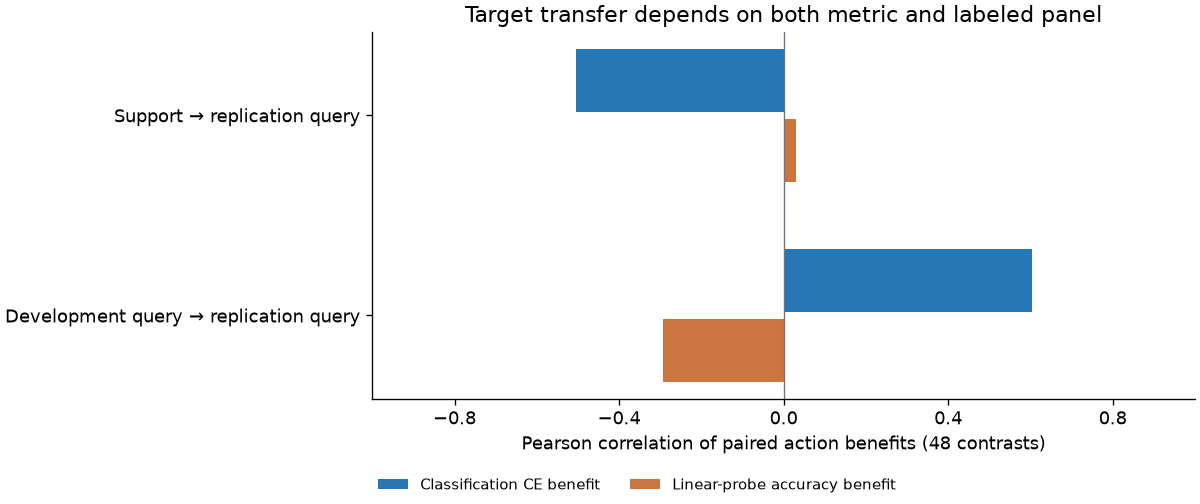

In [5]:
p = pd.DataFrame(D['transfer']); sources = p.source.drop_duplicates().tolist()
fig, ax = plt.subplots(figsize=(10, 4.2), layout='constrained')
bars(ax, sources, [(target, p[p.target == target].set_index('source').loc[sources, 'correlation'].to_numpy(), color)
                  for target, color in [('Classification CE benefit', BLUE), ('Linear-probe accuracy benefit', ORANGE)]],
     'Pearson correlation of paired action benefits (48 contrasts)')
ax.set_xlim(-1, 1); ax.set_title('Target transfer depends on both metric and labeled panel')
finish(fig, '04_target_transfer')


## 5. The strongest local lead: labeled, AdamW-aware CE prediction
Fit a task head on one support panel, measure its CE gradient on a disjoint panel, and project the **virtual AdamW encoder update** onto that gradient. Compare the forecast with the actual one-update CE change. A third support panel checks transfer. Actions use 8 or 24 replay images, contrasted with 16, at matched 32-image update work.

**The formula for the horizontal axis** is the predicted advantage over replay 16:

$$
\widehat{b}_a = -g_B^\top\left(\Delta\theta_a-\Delta\theta_{16}\right),
\qquad g_B=\nabla_\theta L_{\mathrm{CE},B}(\theta).
$$

- $\theta$: the encoder parameters at the saved parent state.
- $L_{\mathrm{CE},B}$: classification CE on labeled support **B**, using a head fitted on support **A** and held fixed.
- $g_B$: the direction and size of CE's sensitivity to encoder parameter changes.
- $\Delta\theta_a$: the virtual AdamW parameter change for action $a\in\{8,24\}$, including the saved optimizer state and the same clipping/weight decay as the actual update.
- $\Delta\theta_{16}$: the corresponding change for the replay-16 baseline.

In words: **compare the proposed and baseline parameter movements, then estimate their effect on classification CE**. This is the first-order approximation $L(\theta+\Delta\theta)\approx L(\theta)+g^\top\Delta\theta$. The forecasting rule has no fitted regression coefficients; it uses labeled support measurements, the trained encoder/head, the candidate SSL batch, and AdamW's state.

**The vertical axis** is the measured advantage after the actual updates:

$$
b_{a,S}=L_{\mathrm{CE},S}(\theta+\Delta\theta_{16})
        -L_{\mathrm{CE},S}(\theta+\Delta\theta_a).
$$

Here $S=B$ in the gradient-support plot and $S=C$ in the third-support plot. **Positive means lower CE than replay 16; negative means higher CE than replay 16.** The plotted predictions and measurements are averaged across draws and support rotations. The approximation is local to one small update; it does not directly forecast accuracy or long-term learning.

The scatter averages two draws and three support rotations, leaving **24 contrasts from 12 parent states**. Pearson **r ≈ 0.604 / 0.545** measures association, not 60% accuracy, explained variance or controller success. These are label-using observations; query labels did not drive the action choice. Each dot is an action contrast, not an independent experiment.


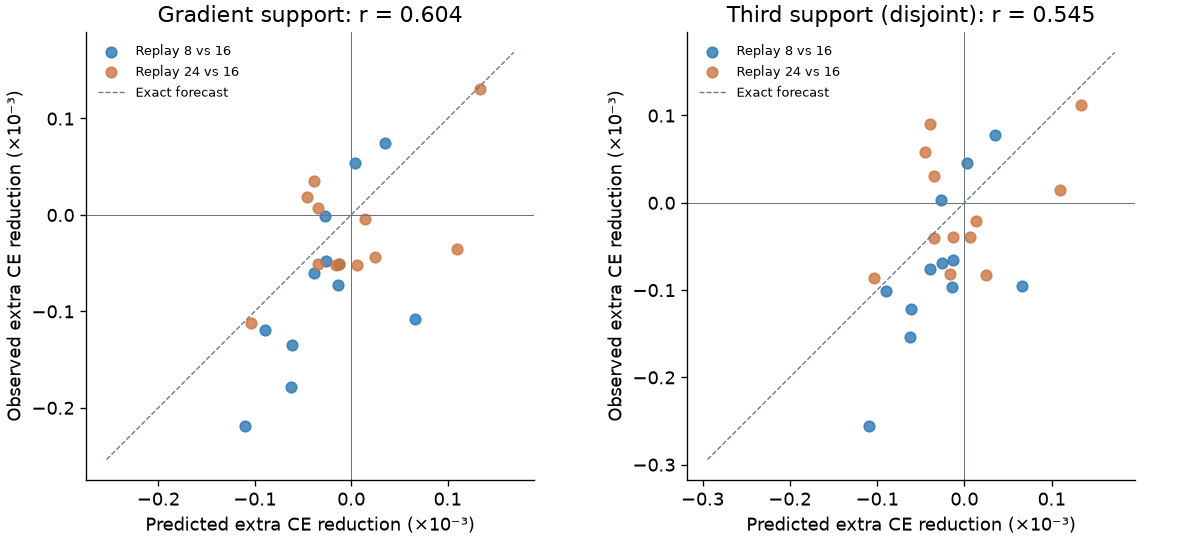

In [6]:
p = pd.DataFrame(D['task_scatter']); cal = pd.DataFrame(D['alignment'])
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), layout='constrained')
for ax, role, title in zip(axes, ['gradient','third'], ['Gradient support','Third support (disjoint)']):
    part = p[p.support_role == role]; x = part.predicted_ce_benefit.to_numpy()*1000; y = part.observed_ce_benefit.to_numpy()*1000
    for action, color in [(8, BLUE), (24, ORANGE)]:
        mask = part.action.to_numpy() == action
        ax.scatter(x[mask], y[mask], s=40, alpha=.8, color=color, label=f'Replay {action} vs 16')
    lo, hi = min(x.min(), y.min()), max(x.max(), y.max()); pad = (hi-lo)*.1
    ax.plot([lo-pad,hi+pad], [lo-pad,hi+pad], '--', color=GREY, linewidth=.8, label='Exact forecast')
    ax.axhline(0, color=GREY, linewidth=.6); ax.axvline(0, color=GREY, linewidth=.6)
    r = np.corrcoef(x, y)[0,1]; ax.set_title(f'{title}: r = {r:.3f}'); ax.set_aspect('equal', adjustable='box')
    ax.set_xlabel('Predicted extra CE reduction (×10⁻³)'); ax.set_ylabel('Observed extra CE reduction (×10⁻³)')
    ax.legend(fontsize=8, frameon=False)
finish(fig, '05_task_gradient_scatter')


## 6. Correlation depends on the horizon and aggregation
The same AdamW forecast is checked against one- and six-update outcomes. Short-term alignment should not be assumed to forecast sustained learning. Averaging only draws retains 72 rotation-specific contrasts and gives the previously reported **0.732 / 0.464**; averaging rotations too gives **0.604 / 0.545** over 24 contrasts.

Both summaries are valid for their stated aggregation, but they answer different measurement questions. Rotations share parents and support images; 72 rows do not mean 72 independent states. Pearson correlation also ignores whether forecast magnitudes are correctly calibrated—the identity lines in Figure 5 reveal that separately.


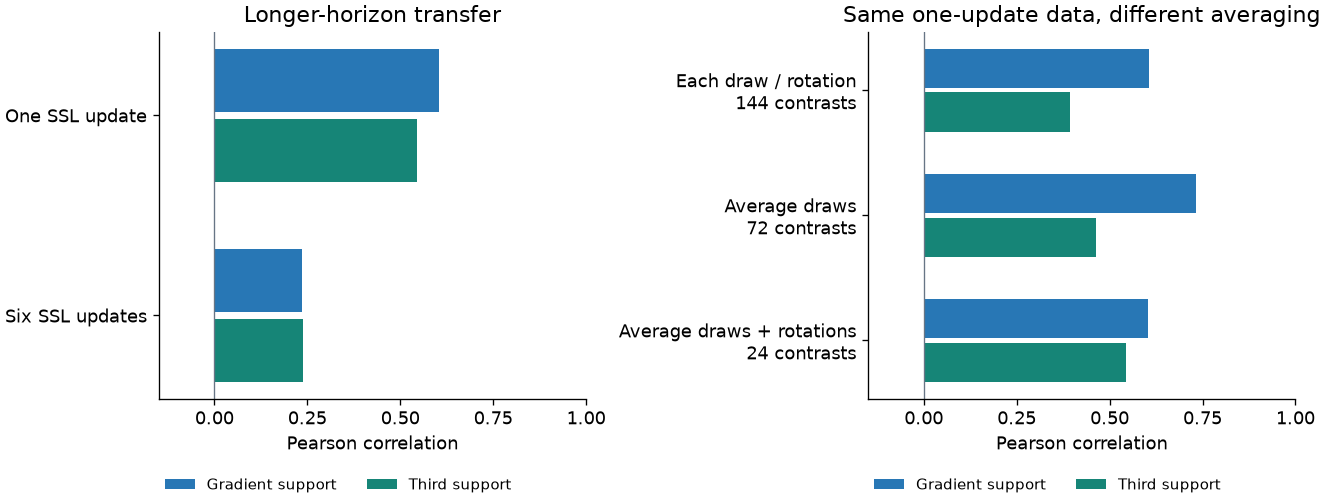

In [7]:
p = pd.DataFrame(D['alignment']); p = p[p.proxy == 'adamw']
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), layout='constrained')
for ax, labels, settings, title in [
    (axes[0], ['One SSL update','Six SSL updates'], [('mean_draws_rotations',1),('mean_draws_rotations',6)], 'Longer-horizon transfer'),
    (axes[1], ['Each draw / rotation\n144 contrasts','Average draws\n72 contrasts','Average draws + rotations\n24 contrasts'],
     [('each_draw_rotation',1),('mean_draws',1),('mean_draws_rotations',1)], 'Same one-update data, different averaging')]:
    series = []
    for role, name, color in [('gradient','Gradient support',BLUE),('third','Third support',TEAL)]:
        values = [float(p[(p.aggregation==agg)&(p.horizon==h)&(p.support_role==role)].correlation.iloc[0]) for agg,h in settings]
        series.append((name, values, color))
    bars(ax, labels, series, 'Pearson correlation'); ax.set_xlim(-.15, 1); ax.set_title(title)
finish(fig, '06_horizon_and_aggregation')


## 7. Controller benefit: the small health-trend gain did not repeat
CE-trained recovery policies were evaluated against **fixed16 uniform replay**. The health-trend policy's balanced linear-probe accuracy gain was **+0.0180 pp** in the original draw and **−0.0596 pp** in the repeat. Its daytime result also reversed. These are draw-level means, not confidence intervals or independent-data replication.

The lesson is narrower than “health never works”: these feature/target/action recipes did not reliably outperform the baseline on reused small-state studies. Local labeled CE alignment remains worth investigating, but a filter needs held-out action prediction **and** repeated accuracy/cost benefit. The ongoing temporal experiment is intentionally excluded from this historical notebook.


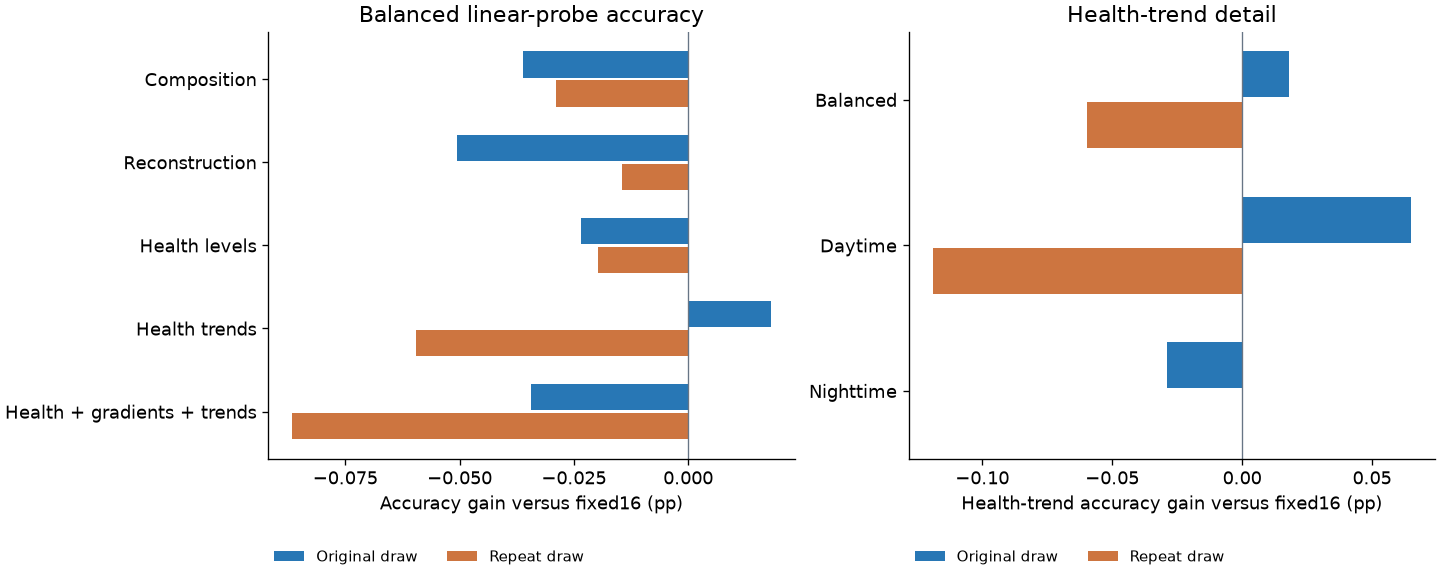

In [8]:
p = pd.DataFrame(D['policies']); labels = p.model.drop_duplicates().tolist()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout='constrained')
bars(axes[0], labels, [(draw, p[p.draw==draw].set_index('model').loc[labels,'accuracy_balanced'].to_numpy(), color)
                      for draw,color in [('Original draw',BLUE),('Repeat draw',ORANGE)]], 'Accuracy gain versus fixed16 (pp)')
axes[0].set_title('Balanced linear-probe accuracy')
part = p[p.model == 'Health trends']; metrics = ['accuracy_balanced','accuracy_A','accuracy_B']
bars(axes[1], ['Balanced','Daytime','Nighttime'], [(draw, part[part.draw==draw].iloc[0][metrics].to_numpy(dtype=float), color)
                                               for draw,color in [('Original draw',BLUE),('Repeat draw',ORANGE)]],
     'Health-trend accuracy gain versus fixed16 (pp)')
axes[1].set_title('Health-trend detail'); finish(fig, '07_controller_repeat')


## Model and sensor guide

| Term | What was measured or fitted |
|---|---|
| Health | Representation rank/dimension, spread or uniformity, occupancy, reconstruction and drift; some recipes add past trends |
| Image × health | Products of candidate-image features and state-level health, allowing state-dependent image ranking |
| Ridge regression | Regularized linear response prediction; early action calibration used penalty 10, later query-target calibration used 100 |
| Composition baseline | Replay allocation and image/domain mixture without adding health measurements |
| MSE skill | Improvement in squared forecast error against predicting zero action benefit; positive correlation can still have negative skill |
| Task-aligned forecast | First-order labeled CE prediction using the actual AdamW update direction, not a fitted health regressor |

**What to retain:** state-dependent interactions were a lead; the response target and its transfer were major bottlenecks; short-horizon labeled CE prediction was stronger than demonstrated controller benefit.

### Saved sources and reproducibility
The next table lists every exact CSV/JSON source and any historical report-hash check. The setup cell verifies all recorded source hashes on rerun. Seven figures are also exported as PNG/SVG. Rebuild with `python -m scripts.build_health_regression_history`, then execute this notebook with `scripts.execute_utility_notebook`. Neither command launches experiments.


In [9]:
from IPython.display import display, Markdown
lines = ['| Saved source | Check |', '|---|---|']
for relative in D['sources']:
    if relative.endswith('report_verification.json'): continue
    checked = 'Historical report hash + notebook hash' if relative in D['historical_report_hash_checks'] else 'Notebook source hash'
    lines.append(f'| [{relative}](../../{relative}) | {checked} |')
display(Markdown('\n'.join(lines)))


| Saved source | Check |
|---|---|
| [outputs/image-utility/20261006-bdd-large-gradient/prediction_h4_fixed_ce_balanced.json](../../outputs/image-utility/20261006-bdd-large-gradient/prediction_h4_fixed_ce_balanced.json) | Notebook source hash |
| [outputs/image-utility/20261006-bdd-response-calibration/analysis.json](../../outputs/image-utility/20261006-bdd-response-calibration/analysis.json) | Notebook source hash |
| [outputs/image-utility/20261008-replay-health-calibration/calibration.csv](../../outputs/image-utility/20261008-replay-health-calibration/calibration.csv) | Notebook source hash |
| [outputs/image-utility/20261008-replay-health-calibration/forecasts.csv](../../outputs/image-utility/20261008-replay-health-calibration/forecasts.csv) | Notebook source hash |
| [outputs/image-utility/20261008-replay-target-transfer/target_transfer.csv](../../outputs/image-utility/20261008-replay-target-transfer/target_transfer.csv) | Notebook source hash |
| [outputs/image-utility/20261008-replay-target-transfer/query_panel_transfer.csv](../../outputs/image-utility/20261008-replay-target-transfer/query_panel_transfer.csv) | Notebook source hash |
| [outputs/image-utility/20261008-replay-task-alignment/task_forecast_calibration.csv](../../outputs/image-utility/20261008-replay-task-alignment/task_forecast_calibration.csv) | Historical report hash + notebook hash |
| [outputs/image-utility/20261008-replay-task-alignment/task_response_contrasts.csv](../../outputs/image-utility/20261008-replay-task-alignment/task_response_contrasts.csv) | Historical report hash + notebook hash |
| [outputs/image-utility/20261008-replay-health-recovery/policy_summary.csv](../../outputs/image-utility/20261008-replay-health-recovery/policy_summary.csv) | Historical report hash + notebook hash |
| [outputs/image-utility/20261008-replay-health-recovery-repeat/policy_summary.csv](../../outputs/image-utility/20261008-replay-health-recovery-repeat/policy_summary.csv) | Historical report hash + notebook hash |